**state ($\sigma$)** ← El estado del gas. Es una matriz con unos y ceros: uno es que está lleno y cero que está vacío.

La energía de un estado está dada por:

$$H(\sigma) = -\epsilon \sum_{i}^{N} \sum_{j \in NN(i)} \sigma_i \sigma_j$$

Buscamos: diferentes valores de $\sigma$ muestreados con una distribución de probabilidad:

$$P(\sigma) = \frac{1}{Z} \exp\left(-\frac{H(\sigma)}{k_B T}\right)$$

$\sigma_0$ ← Estado inicial de nuestro sistema

**Propuesta:** $\sigma' = \sigma + \delta\sigma$ ← Definimos un segundo estado $\sigma'$, cercano al estado actual $\sigma$

**Aceptación:** Aceptamos $\sigma'$ con una probabilidad $p = \min\left(1, \dfrac{P(\sigma')}{P(\sigma)}\right)$

$$\frac{P(\sigma')}{P(\sigma)} = \frac{\frac{1}{Z}e^{-H(\sigma')/k_BT}}{\frac{1}{Z}e^{-H(\sigma)/k_BT}} = \exp\left(-\frac{H(\sigma') - H(\sigma)}{k_B T}\right) = e^{-\Delta H / k_B T}$$

$\sigma_0$ ← Estado inicial de nuestro sistema

- Un ciclo $M$ veces: ← ¿Cuántos diferentes valores de $\sigma$ queremos?
  - En un ciclo $N$ veces [1 paso de Monte Carlo]:
    - **Propuesta:** $\sigma' = \sigma + \delta\sigma$ ← Definimos un segundo estado $\sigma'$, cercano al estado actual $\sigma$
    - **Aceptación:** Aceptamos $\sigma'$ con una probabilidad

      $$p = \min\left(1, \exp\left(\frac{-\Delta H}{k_B T}\right)\right)$$

  - Guardamos $\sigma$

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm.auto as tqdm

c:\Users\Emil\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
rng= np.random.default_rng(seed = 12345)

L=30
state0 = rng.choice([0,1], size=(L,L))

def propose(state):
    state_new = np.copy(state)
    [Lx,Ly] = np.shape(state)

    i = rng.integers(Lx, size=[2])
    j = rng.integers(Ly, size=[2])

    state_new[i[1],j[1]] = state[i[0],j[0]]
    state_new[i[0],j[0]] = state[i[1],j[1]]

    return state_new

def calculate_energy(state):
    state_right = np.roll(state, shift = 1, axis = 1)
    state_down = np.roll(state, shift=1, axis=0)

    return np.sum(state_right * state0 + state_down*state0)
    
calculate_energy(state0)

np.int64(393)

100%|██████████| 1000/1000 [01:14<00:00, 13.47it/s]


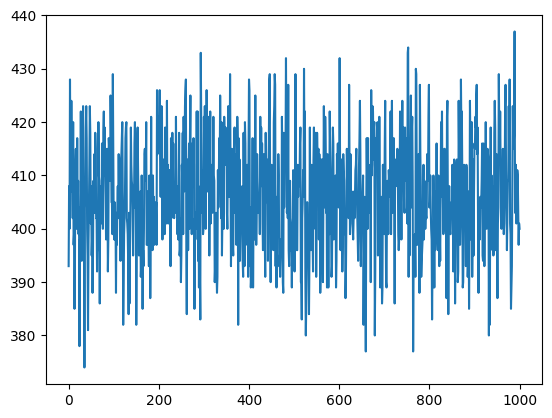

In [21]:
state = state0
energy = calculate_energy(state)
temp = 1

state_chain = [state0]
energy_chain = [energy]

[Lx,Ly] = np.shape(state)

for mc_i in tqdm.tqdm(range(1000)):
    for i in range(Lx*Ly):
        new_state = propose(state)
        new_energy = calculate_energy(state)

        if new_energy <= energy:
            state = new_state
            energy = new_energy
        
        else:
            p = np.exp(-(new_energy - energy)/temp)
            if rng.choice([True,False], p=[p, 1-p]):
                state = new_state
                energy = new_energy

    state_chain.append(state)
    energy_chain.append(energy)

plt.plot(np.array(energy_chain))

## Parte 1. Modelo de Ising

El modelo de Ising es una forma de simular transiciones de fase continuas. Originalmente fue propuesto para describir el comportamiento de materiales ferromagnéticos, y es uno de los primeros modelos de transiciones de fase que se resolvieron analíticamente. El modelo consiste en definir $N$ spins $\sigma$ en una red, que pueden tomar los valores $\sigma \in [-1, 1]$. La energía interna del sistema está dada por el Hamiltoniano:

$$
H = -J \sum_i \sum_{j=\mathbb{N}} \sigma_i \sigma_j - B \sum_i \sigma_i
$$

donde $\mathbb{N}$ es el conjunto de los primeros vecinos del spin $i$.

Realiza una simulación del modelo de Ising en una red cuadrada usando el algoritmo de Metrópolis. Considera que $B=0$ y $J=1$. Observa la energía para confirmar que la simulación está llegando a un estado estacionario. 

- Representa las configuraciones finales como una imagen para casos con temperatura reducida $T = 1.5$, $2.3$ y $T = 3$.
- Grafica la energía y la magnetización como función del número de pasos de Monte Carlo.
- Utilizando solo datos del sistema en estado estacionario, calcula la energía final promedio y el valor absoluto de la magnetización. También calcula la varianza de ambas cantidades.
- Barre el rango entre $T = 1.5$ y $3$, y haz una gráfica de las cuatro cantidades calculadas vs. temperatura.
    - Tanto la energía como la magnetización deberían mostrar un punto de inflexión cerca de $T=2.3$, y las fluctuaciones de ambas deberían mostrar un pico. Este es el punto crítico del modelo.
- ¿Cómo se comparan los estados que están debajo y encima del punto crítico?


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tqdm.auto as tqdm
from scipy.constants import k 

# Parametros
T = [0, 100 , 270, 335] # Temperatura
k # Constante de boltzman
num_spins = len(askjdflaksdf)

print(f"Valor de la constante de Boltzman {k}")

def energy():
    pass

# Probabilidad del estado
def probability_state(state, N = num_spins):
    pass

def probability_acceptation(sigma, sigma_prime, k, T):
    # prob_acc = probability_state(sigma)/probability_state(sigma_prime) 
    prob_acc = np.exp(-(energy(sigma_prime) - energy(sigma))/(k*T))


    pass

def metropolis_ising(M,N):

    for i in range(M):
        for j in tqdm.tqdm(range (N)):
            state = []  
            if prob_sig_prime <= prob_sig:
                state = state_prime
            elif rand1 < acept_probabilidad:
                state = state_prime

    pass


# # Funcion del Hamiltoniano
# def Hamiltonian():
#     pass





Valor de la constante de Boltzman 1.380649e-23
